In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "1"
os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = "0.9"
os.environ["JAX_COMPILATION_CACHE_DIR"] = "/system/user/volkmann/jax_playground/jax_cache"

import sys
sys.path.append("/system/user/volkmann/vectorized_autobounds/")

In [2]:
import jax
jax.config.update("jax_enable_x64", True)  # Enable 64-bit precision
jax.config.update("jax_compilation_cache_dir", "/system/user/volkmann/jax_playground/jax_cache")
from jax.experimental.compilation_cache import compilation_cache as cc
cc.set_cache_dir("/system/user/volkmann/jax_playground/jax_cache")

from matplotlib import pyplot as plt
import numpy as np
import autobound.jax as ab
import jax.numpy as jnp
import jax.random as jr
import optax
import equinox as eqx
from typing import Callable

from functools import partial
import k3d
import numpy as np
import math

In [3]:
from utils.ab_bounds_conversion import autobounds_coefficients_to_power_series
from utils.bernstein_polynomial_transform_nd import transform_power_series_interval_to_bernstein

from utils.autobounds_roots import transform_2nd_order_tensor
from implicitSurfaces.autoboundedImplicit import autoboundedImplicit

from rayMarcher.sampler import generate_antialiased_ray, generate_random_unit_ray
from utils.autobounds_roots import roots_2nd_order_tensor, roots_2nd_order_polynomial
from utils.bernstein_polynomial_transform_nd import power_series_polynomial

#### Neural Network

In [4]:
from typing import NamedTuple

class Params(NamedTuple):
    w1: jnp.ndarray  # [d_in, d_hidden]
    b1: jnp.ndarray  # [d_hidden]
    w2: jnp.ndarray  # [d_hidden, d_hidden]
    b2: jnp.ndarray  # [d_hidden]
    w3: jnp.ndarray  # [d_hidden, d_hidden]
    b3: jnp.ndarray  # [d_hidden]
    w4: jnp.ndarray  # [d_hidden, d_out]
    b4: jnp.ndarray  # [d_out]


def init_params(d_in, d_hidden, d_out, key):
    w1_key, w2_key, w3_key, w4_key, b1_key, b2_key, b3_key, b4_key = jax.random.split(key, num=8)
    return Params(
        w1=jax.random.uniform(key=w1_key, shape=[d_in, d_hidden], minval=-1/math.sqrt(d_in), maxval=1/math.sqrt(d_in)),
        b1=jax.random.uniform(key=b1_key, shape=[d_hidden], minval=-1/math.sqrt(d_hidden), maxval=1/math.sqrt(d_hidden)),
        w2=jax.random.uniform(key=w2_key, shape=[d_hidden, d_hidden], minval=-1/math.sqrt(d_hidden), maxval=1/math.sqrt(d_hidden)),
        b2=jax.random.uniform(key=b2_key, shape=[d_hidden], minval=-1/math.sqrt(d_hidden), maxval=1/math.sqrt(d_hidden)),
        w3=jax.random.uniform(key=w3_key, shape=[d_hidden, d_hidden], minval=-1/math.sqrt(d_hidden), maxval=1/math.sqrt(d_hidden)),
        b3=jax.random.uniform(key=b3_key, shape=[d_hidden], minval=-1/math.sqrt(d_hidden), maxval=1/math.sqrt(d_hidden)),
        w4=jax.random.uniform(key=w4_key, shape=[d_hidden, d_out], minval=-1/math.sqrt(d_hidden), maxval=1/math.sqrt(d_hidden)),
        b4=jax.random.uniform(key=b4_key, shape=[d_out], minval=-1/math.sqrt(d_out), maxval=1/math.sqrt(d_out)),
    )


def neural_network(params, x):
    x = x @ params.w1 + params.b1
    x = jax.nn.swish(x)
    x = x @ params.w2 + params.b2
    x = jax.nn.swish(x)
    x = x @ params.w3 + params.b3
    x = jax.nn.swish(x)
    x = x @ params.w4 + params.b4

    return x

#### Implicit definition

In [5]:
@partial(jax.jit, static_argnames=['radius'])
def sdf_sphere_jax(x: jnp.ndarray, radius: float) -> jnp.ndarray:
    return jnp.linalg.norm(x, axis=-1) - radius


@partial(jax.jit, static_argnames=['r', 'R'])
def sdf_torus_jax(x: jnp.ndarray, r: float, R: float) -> jnp.ndarray:
    q = jnp.sqrt(jnp.pow(x[0], 2) + jnp.pow(x[2], 2)) - R
    return jnp.sqrt(jnp.pow(q, 2) + jnp.pow(x[1], 2)) - r

def twistOperation(fn: Callable, k: float) -> Callable:
    @jax.jit
    def twist(x: jnp.array):
        c = jnp.cos(k * x[1])
        s = jnp.sin(k * x[1])
        m = jnp.array([[c, 0., -s], [s, 0., c], [0., 1., 0.]])
        return fn(jnp.matmul(m, x))
    return twist

#### Model fitting

In [6]:
def train(model, params, optim, ndim, gt_fn, n_steps, bbox, subkey):
    opt_state = optim.init(params)

    def loss_fn(params, X):
        pred_y = jax.vmap(model, in_axes=(None, 0))(params, X)
        true_y = jax.vmap(gt_fn)(X)
        return jnp.mean(jnp.pow((pred_y[:, 0] - true_y), 2))

    @jax.jit
    def step(params, opt_state, X):
        loss, grads = jax.value_and_grad(loss_fn, argnums=0)(params, X)
        update, opt_state = optim.update(grads, opt_state)
        params = optax.apply_updates(params, update)
        return params, opt_state, loss
    
    @jax.jit
    def point_sampler(key):
        key, subkey = jax.random.split(key)
        return jax.random.uniform(key, (10000, ndim), minval=bbox[0], maxval=bbox[1]), subkey

    for iter in range(0, n_steps):
        XY, subkey = point_sampler(subkey)
        params, opt_state, loss = step(params, opt_state, XY)
        if iter % 100 == 0:
            print(f"Iteration {iter}, loss: {loss}")
    return params

In [7]:
LEARNING_RATE = 1e-2
STEPS = 1000
RADIUS_OUTER = 0.5
RADIUS_INNER = 0.2
NDIM = 3
HIDDEN_DIM = 128

params = init_params(NDIM, HIDDEN_DIM, 1, key=jax.random.PRNGKey(1))
trained_params = init_params(NDIM, HIDDEN_DIM, 1, key=jax.random.PRNGKey(2))
optim = optax.adam(LEARNING_RATE)

In [8]:
trained_params = train(
    model=neural_network,
    params=params,
    optim=optim,
    ndim=NDIM,
    gt_fn=twistOperation(partial(sdf_torus_jax, r=RADIUS_INNER, R=RADIUS_OUTER), k=5.),
    n_steps=STEPS,
    bbox=(-1, 1),
    subkey=jax.random.PRNGKey(0)
)

Iteration 0, loss: 0.07253157730667024
Iteration 100, loss: 0.018339494139976223
Iteration 200, loss: 0.01773830886025419
Iteration 300, loss: 0.01744920235857722
Iteration 400, loss: 0.013476172853124987
Iteration 500, loss: 0.01193957534919173
Iteration 600, loss: 0.005153241516816891
Iteration 700, loss: 0.0015481502761929568
Iteration 800, loss: 0.000845985246950977
Iteration 900, loss: 0.0005736632693658498


### Marching Cubes

In [9]:
x0 = 0.0
offset = 1.0
level_set = 0.0


x_vals = jnp.linspace(x0 - offset, x0 + offset, 128)
y_vals = jnp.linspace(x0 - offset, x0 + offset, 128)
z_vals = jnp.linspace(x0 - offset, x0 + offset, 128)
X, Y, Z = jnp.meshgrid(x_vals, y_vals, z_vals)

grid_points = jnp.stack([X.ravel(), Y.ravel(), Z.ravel()], axis=-1)
fn_vals = jax.vmap(neural_network, in_axes=(None, 0))(trained_params, grid_points).reshape(X.shape)
#fn_vals = jax.vmap(twistOperation(partial(sdf_torus_jax, r=RADIUS_INNER, R=RADIUS_OUTER), k=5.))(grid_points).reshape(X.shape)
fn_vals_normalized = (fn_vals - jnp.min(fn_vals)) / (jnp.max(fn_vals) - jnp.min(fn_vals))
fn_vals_normalized_np = fn_vals_normalized.astype(np.float64)
level_set_normalized = (level_set - jnp.min(fn_vals)) / (jnp.max(fn_vals) - jnp.min(fn_vals))

In [10]:
plot = k3d.plot()

iso_surf = k3d.marching_cubes(
    fn_vals_normalized_np, 
    level=level_set_normalized.astype(np.float32).item(),
    xmin=x0 - offset, xmax=x0 + offset,
    ymin=x0 - offset, ymax=x0 + offset,
    zmin=x0 - offset, zmax=x0 + offset,
    color=0x00ff00, 
    opacity=1.)
plot += iso_surf

In [11]:
plot.display()

Output()

## Rendering

In [14]:
from rayMarcher.integrator import Integrator
from rayMarcher.materials import Material
from rayMarcher.camera import Camera

camera_dict = {
    'image_width': 350,
    'image_height': 200,
    'defocus_angle': 0.0,
    'focus_distance': 1.0,
    'vfov': 90.0,
    'lookfrom': jnp.array([1.2, 0.0, 0.0]),
    'lookat': jnp.array([-1.2, 0., 0.]),
    'vup': jnp.array([0., 1.0, 0.0]),
}

In [15]:
def normal_at_point(point: jnp.ndarray) -> jnp.ndarray:
    grad_fn = jax.jacobian(ab_implicit.fn)
    normal = grad_fn(point)
    normal = normal / jnp.linalg.norm(normal)
    return normal.squeeze()

In [16]:
ab_implicit = autoboundedImplicit(lambda x: neural_network(trained_params, x), autobounds_max_degree=2, level_set=0.0, classification_flag='bernstein')
partial_ab_intersec_fn = partial(ab_implicit.ray_surface_intersection_single, max_iterations=40, max_distance=10., init_interval=1.0, unroll=False, level_set_eps=1e-3)

In [17]:
partial_ab_intersec_batch_fn = partial(ab_implicit.ray_surface_intersection_batch, max_iterations=200, max_distance=10., init_interval=1.0, level_set_eps=1e-3)

In [18]:
camera = Camera.setup_Camera(**camera_dict)

distance_functions = [partial_ab_intersec_fn]
normals_functions = [normal_at_point]

integrator = Integrator(
    camera=camera, materials={}, 
    background_color=jnp.array([0.5, 0.7, 1.0]),
    scene_intersection_fn=partial_ab_intersec_batch_fn,
    scene_dist_fns=distance_functions,
    scene_normal_fns=normals_functions,
    samples_per_pixel=50,
    max_depth=8,
    epsilon=1e-4,
    max_sphere_trace_dist=100.0,
)

In [24]:
jitted_render_sphere_trace = jax.jit(integrator.render_sphere_trace)

In [25]:
rendered_image, n_steps_per_pixel = jitted_render_sphere_trace(jax.random.PRNGKey(42))

In [26]:
rendered_image_np = np.array(rendered_image)

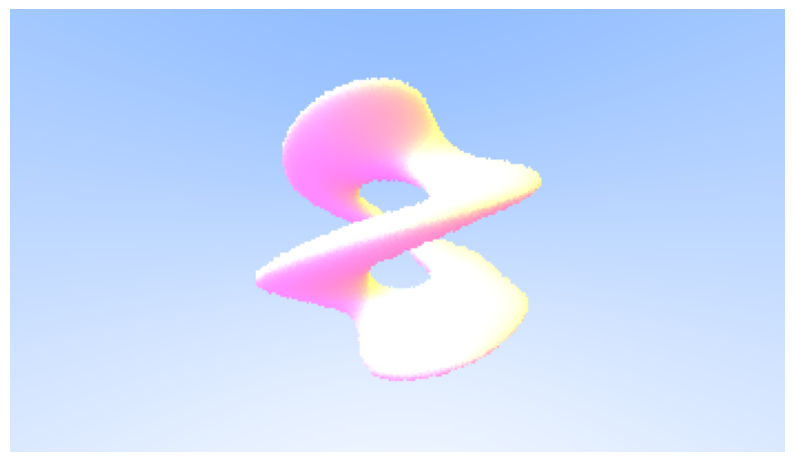

In [27]:
plt.figure(figsize=(10, 15))
plt.imshow(rendered_image_np)
plt.axis('off')
plt.show()

In [18]:
%timeit jitted_render_sphere_trace(jax.random.PRNGKey(42))[0].block_until_ready()

KeyboardInterrupt: 

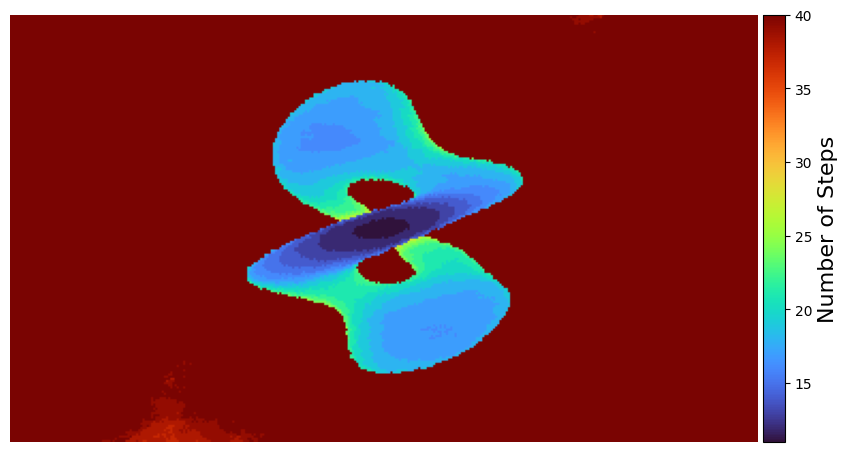

In [28]:
from mpl_toolkits.axes_grid1 import make_axes_locatable

fig, ax = plt.subplots(figsize=(10, 15))
im = ax.imshow(n_steps_per_pixel, cmap='turbo')
ax.axis('off')

divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="3%", pad=0.05)  # colorbar width; height matches image
cb = plt.colorbar(im, cax=cax)
cb.set_label('Number of Steps', fontsize=16)

plt.show()

In [ ]:
N_pixels = integrator.camera.image_width * integrator.camera.image_height


: 

: 

In [22]:
from rayMarcher.utils import normalize
from rayMarcher.sampler import generate_antialiased_ray

def render_sphere_trace(key: jr.PRNGKey) -> jnp.array:
    H, W = integrator.camera.image_height, integrator.camera.image_width
    i_coords, j_coords = jnp.meshgrid(jnp.arange(W), jnp.arange(H))
    i_coords = i_coords.flatten()
    j_coords = j_coords.flatten()
    pixel_keys = jr.split(key, H * W)

    ray_origins, ray_directions = jax.vmap(generate_antialiased_ray, in_axes=(None, 0, 0, 0))(integrator.camera, i_coords, j_coords, pixel_keys)

    unit_direction_background = jax.vmap(normalize)(ray_directions)
    t = (0.5 * (unit_direction_background[:, 1] + 1.0))[:, None]
    background_color = (1.0 - t) * jnp.array([1.0, 1.0, 1.0]) + t * integrator.background_color
    niters, hit_points, hits = integrator.scene_intersection_fn(ray_origins[0, :], ray_directions)
    hit_normals = jax.vmap(integrator.scene_normal_fns[0])(hit_points)
    test_color = jnp.clip(0.5 * hit_normals + jnp.array([1., 1., 1.]), 0.0, 1.0)
    colors_flat = jnp.where(hits[:, None], test_color, background_color)
    image = colors_flat.reshape((H, W, 3))
    niter = niters.reshape((H, W))
    return image, niter

In [23]:
rendered_image, niter_rendering = render_sphere_trace(key=jax.random.PRNGKey(3))

In [26]:
niter_rendering.shape[0] * niter_rendering.shape[1]

70000

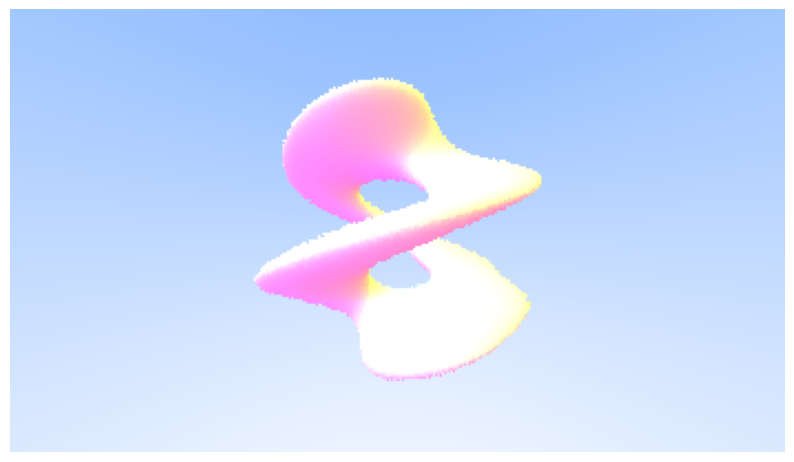

In [24]:
plt.figure(figsize=(10, 15))
plt.imshow(rendered_image)
plt.axis('off')
plt.show()

In [31]:
N_pixels = integrator.camera.image_width * integrator.camera.image_height
ray_origins = jnp.zeros((N_pixels, 3))
jit_vmap_tb = jax.jit(jax.vmap(ab_implicit.taylor_bounds))
jit_vmap_tb(ray_origins, (ray_origins - 1.0, ray_origins + 1.0))

TaylorBounds(f=<function <lambda> at 0x7f80d02c1440>, x0=Array([[0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       ...,
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.]], dtype=float64), x_trust_region=(Array([[-1., -1., -1.],
       [-1., -1., -1.],
       [-1., -1., -1.],
       ...,
       [-1., -1., -1.],
       [-1., -1., -1.],
       [-1., -1., -1.]], dtype=float64), Array([[1., 1., 1.],
       [1., 1., 1.],
       [1., 1., 1.],
       ...,
       [1., 1., 1.],
       [1., 1., 1.],
       [1., 1., 1.]], dtype=float64)), coefficients=(Array([[0.22177982],
       [0.22177982],
       [0.22177982],
       ...,
       [0.22177982],
       [0.22177982],
       [0.22177982]], dtype=float64), Array([[[0.1153861 , 0.38277788, 0.11403066]],

       [[0.1153861 , 0.38277788, 0.11403066]],

       [[0.1153861 , 0.38277788, 0.11403066]],

       ...,

       [[0.1153861 , 0.38277788, 0.11403066]],

       [[0.1153861 , 0.38277788, 0.11403066]],

       [[0.1153861 , 

In [33]:
%timeit jit_vmap_tb(ray_origins, (ray_origins - 1.0, ray_origins + 1.0)).coefficients[0].block_until_ready()

913 ms ± 238 μs per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [34]:
nn_jit_vmap = jax.jit(jax.vmap(ab_implicit.fn))
nn_jit_vmap(ray_origins)

Array([[0.22177982],
       [0.22177982],
       [0.22177982],
       ...,
       [0.22177982],
       [0.22177982],
       [0.22177982]], dtype=float64)

In [35]:
%timeit nn_jit_vmap(ray_origins).block_until_ready()

11.4 ms ± 71.2 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)
